# [Lab Session 3](fourier.ipynb)


In [3]:
%pip install scikit-image

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.9 MB 2.9 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/11.9 MB 2.7 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/11.9 MB 3.4 MB/s eta 0:00:03
   ---------- ----------------------------- 3.1/11.9 MB 3.8 MB/s eta 0:00:03
   ------------- -------------------------- 3.9/11.9 MB 3.9 MB/s eta 0:00:03
   ----------------- ---------------------- 5.2/11.9 MB 4.3 MB/s eta 0:00:02
   ---------------------- ----------------- 6.6/11.9 MB 4.6 MB/s eta 0:00:02
   ------------------------- -------------- 7.6/11.9 MB 4.6 MB/s eta 0:00:01
   ----------------------------- ---------- 8.9/11.9 MB 4.8 MB/s eta 0:00:01
   ---------------------------------- ----- 10.2/11.9 MB 5.0 MB/s eta 0:00:01
   ---------------------------------------  11.8/11.9 MB 5.2 MB/s eta 0:00:01
   ---------------------------------------- 11.9/11.9 MB 5.1 MB/s eta 0:00:00
   

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


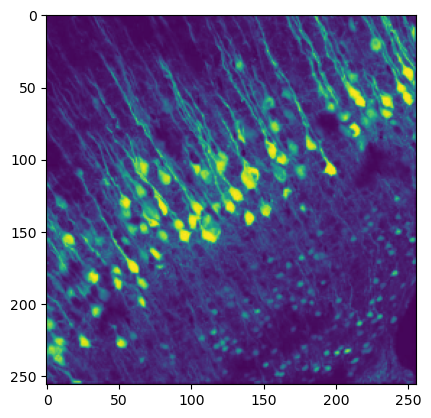

In [88]:
cell_img = plt.imread('data/cells.png')
c_img_r = resize(cell_img, (256, 256), preserve_range=True)

plt.imshow(c_img_r)

In [89]:
print(c_img_r.shape)

(256, 256)


**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [90]:
cell_ft = np.fft.fft2(c_img_r)

print(cell_ft.dtype)

complex64


**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [91]:
amp = np.abs(cell_ft)
phase = np.angle(cell_ft)

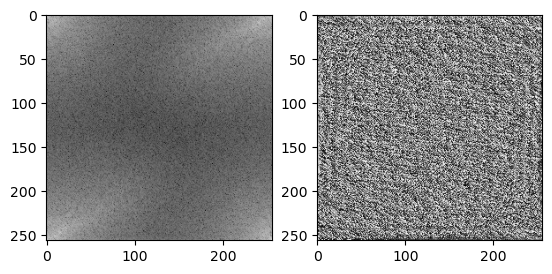

In [92]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amp),cmap= 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


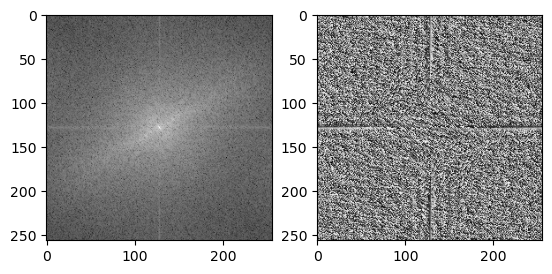

In [93]:
cell_ft_shifted = np.fft.fftshift(cell_ft)

amp2= np.abs(cell_ft_shifted)
phase2= np.angle(cell_ft_shifted)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amp2), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase2, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


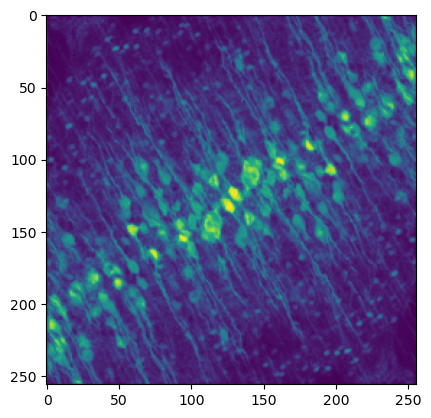

In [94]:
cell_ft_unshift = np.fft.ifftshift(cell_ft_shifted)

cell_ft_restore = np.fft.ifft2(cell_ft_unshift.real)
plt.imshow(cell_ft_restore.real)

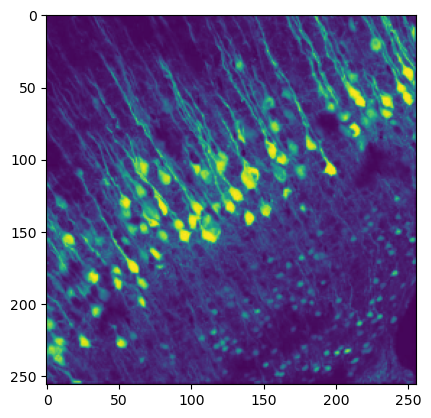

In [95]:
plt.imshow(c_img_r)

#for comparison, they look very similar

---


**[Task 2 (a).]()** Load the brain MR image.


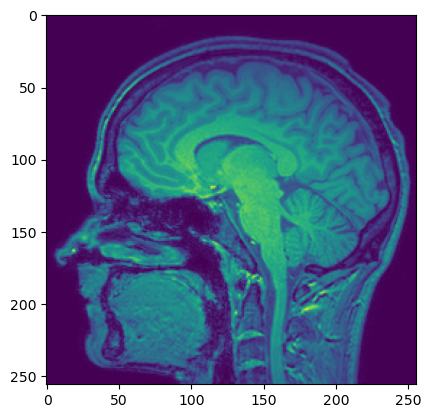

In [96]:
brain_img = plt.imread('data/brain_mri.png')

plt.imshow(brain_img)

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


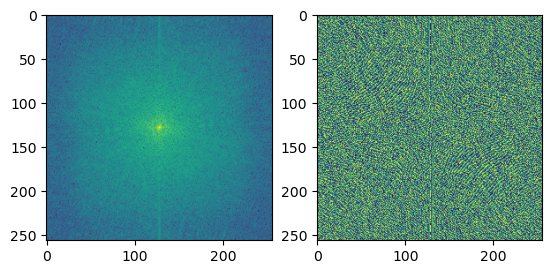

In [112]:
brain_r = resize(brain_img, c_img_r.shape, preserve_range=True)

brain_ft = np.fft.fft2(brain_r)

brain_ft_shift = np.fft.fftshift(brain_ft)

#amp and phase of not shifted brain_ft
amp3 = np.abs(brain_ft)
phase3 = np.angle(brain_ft)

#amp and phase of shifted brain_ft_shifted
amp4 = np.abs(brain_ft_shift)
phase4 = np.angle(brain_ft_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amp4))
plt.subplot(1, 2, 2)
plt.imshow(phase4)

In [98]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


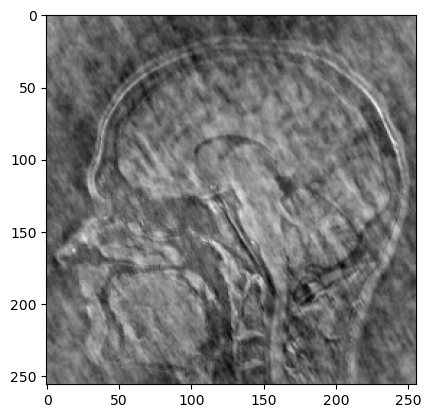

In [99]:
#not shifted amp cell and phase brain

ba_cp_complex = to_complex_array(amp, phase3)
ba_cp_comp_ift = np.fft.ifft2(ba_cp_complex).real

plt.imshow(ba_cp_comp_ift, cmap='gray')

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


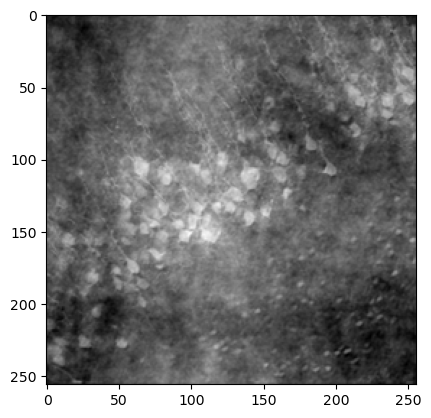

In [100]:
#not shifted amp brain and phase cell

bp_ca_complex = to_complex_array(amp3, phase)
bp_ca_comp_ift = np.fft.ifft2(bp_ca_complex).real

plt.imshow(bp_ca_comp_ift, cmap='gray')

phase carries more info

---


**[Task 3 (a).]()** Create a lowpass filter mask.


In [106]:
filter_size = 50

print(brain_r.shape)

(256, 256)


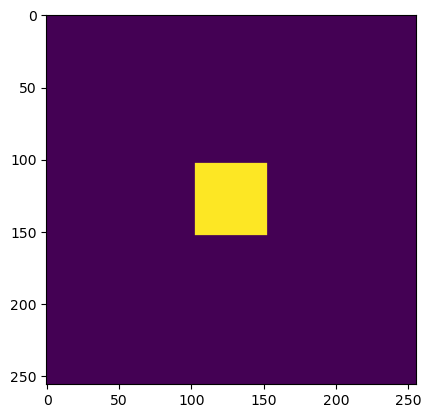

In [107]:
low_pass_mask = np.zeros(brain_r.shape)

cy, cx = np.array(low_pass_mask.shape) // 2

low_pass_mask[cy-filter_size//2:cy+filter_size//2,
              cx-filter_size//2:cx+filter_size//2] = 1

plt.imshow(low_pass_mask)


**[Task 3 (b).]()** Create a highpass filter maks.


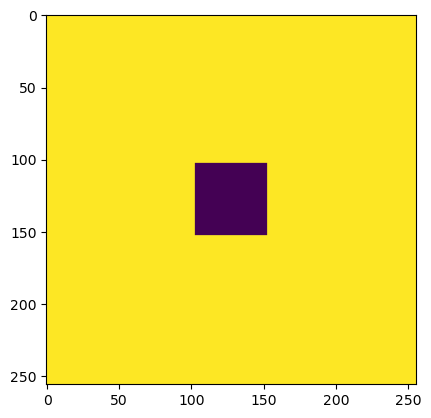

In [108]:
high_pass_mask = 1 - low_pass_mask

plt.imshow(high_pass_mask)

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


C:\Users\gusta\AppData\Local\Temp\ipykernel_10316\3094017244.py:8: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(brain_r_low))
C:\Users\gusta\AppData\Local\Temp\ipykernel_10316\3094017244.py:10: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(brain_r_high))


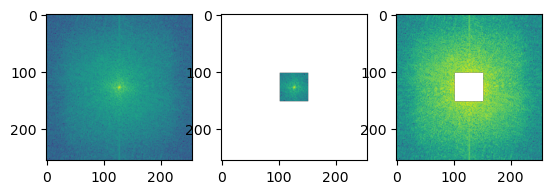

In [113]:
brain_r_high = high_pass_mask * amp4
brain_r_low = low_pass_mask * amp4

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(np.log(amp4))
plt.subplot(1, 3, 2)
plt.imshow(np.log(brain_r_low))
plt.subplot(1, 3, 3)
plt.imshow(np.log(brain_r_high))


**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


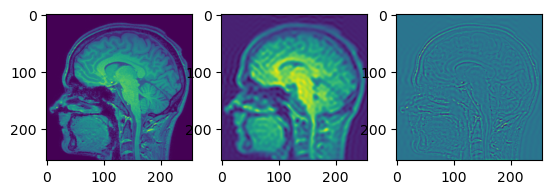

In [114]:
low_complex = to_complex_array(brain_r_low, phase4)
high_complex = to_complex_array(brain_r_high, phase4)

low_complex_unshift = np.fft.ifftshift(low_complex)
high_complex_unshift = np.fft.ifftshift(high_complex)

low_ift = np.fft.ifft2(low_complex_unshift).real
high_ift = np.fft.ifft2(high_complex_unshift).real

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(brain_r)
plt.subplot(1, 3, 2)
plt.imshow(low_ift)
plt.subplot(1, 3, 3)
plt.imshow(high_ift)


---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [118]:
dft = np.zeros(brain_r.shape, dtype=np.complex64)

def my_dft(img):
    M, N = img.shape
    dft = np.zeros(img.shape, dtype=complex)

    for u in range(M):
        for v in range(N):
            for x in range(M):
                for y in range(N):
                    dft[u, v] += img[x, y] * np.exp(
                        -2j * np.pi * (u*x/M + v*y/N)
                    )

            dft[u, v] /= (M * N)

    return dft

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [119]:
def my_idft(dft):
    M, N = dft.shape
    idft = np.zeros(dft.shape, dtype=complex)

    for u in range(M):
        for v in range(N):
            for x in range(M):
                for y in range(N):
                    idft[u, v] += dft[x, y] * np.exp(
                        2j * np.pi * (u*x/M + v*y/N)
                    )

            idft[u, v] /= (M * N)

    return idft

Due to high computational costs, we need to resize the image.


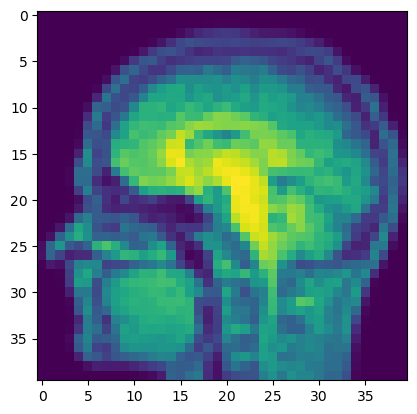

In [126]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img)

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


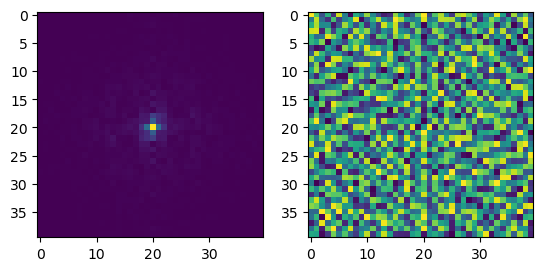

In [127]:
test_dft = my_dft(test_img)
shifted_dft= np.fft.fftshift(test_dft)

plt.subplot(1, 2, 1)
plt.imshow(np.log1p(np.abs(shifted_dft)))

plt.subplot(1, 2, 2)
plt.imshow(np.angle(shifted_dft))

plt.show()

**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


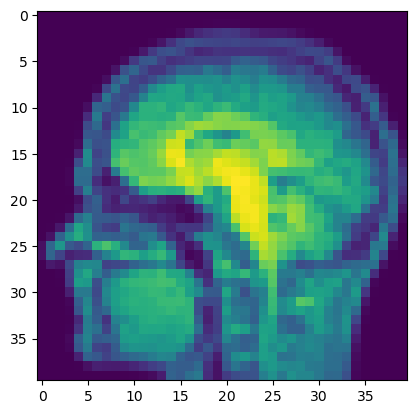

In [125]:
test_idtf = my_idft(test_dtf)

plt.imshow(np.log1p(np.abs(test_idtf)))

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [161]:
brain_small = resize(brain_img, (40, 40))

test_dft = test_dft.astype(np.complex64)

small_brain_ft = np.fft.fft2(brain_small, norm = 'forward')

print(np.allclose(small_brain_ft, test_dft))

True


**[Task 4 (f).]()** Round the arrays and compare them again.


In [162]:
mean_diff = np.mean(np.abs(test_dft - small_brain_ft))
print(mean_diff)

2.668462e-10


In [163]:
print(np.mean(np.abs(test_dft - small_brain_ft)))
print(np.max(np.abs(test_dft - small_brain_ft)))

2.668462e-10
1.4901161e-08


In [164]:
for i in range(1, 11):
    dft_rounded = np.round(test_dft, i)
    fft_rounded = np.round(small_brain_ft, i)

    print(i, (dft_rounded == fft_rounded).all())

1 True
2 True
3 True
4 True
5 True
6 False
7 False
8 False
9 False
10 False


In [ ]:
dft_rounded = np.round(test_dft, 5)
fft_rounded = np.round(small_brain_ft, 5)

# Find positions where values differ
different = np.argwhere(dft_rounded != fft_rounded)

print("Number of different elements:", len(different))

# Show the first difference
if len(different) > 0:
    x, y = different[0]
    print("DFT:", test_dft[x, y])
    print("FFT:", small_brain_ft[x, y])
    print("Rounded DFT:", dft_rounded[x, y])
    print("Rounded FFT:", fft_rounded[x, y])

Number of different elements: 1600
DFT: (0.23930975179756675+0j)
FFT: (0.23930974+0j)
Rounded DFT: (0.23931+0j)
Rounded FFT: (0.23931+0j)


In [165]:
print(test_dft.dtype)
print(small_brain_ft.dtype)
print(brain_small.dtype)

complex64
complex64
float32


In [166]:
dft_rounded = np.round(test_dft, 1)
fft_rounded = np.round(small_brain_ft, 1)

print((dft_rounded == fft_rounded).all())

True


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
